# S06c: Case-level model comparison

This notebook presents the results of `s06c_model_comparison.py`, which reruns the case-level models of S06 on corrected data and compares eight regressors under one protocol.

**What changed from S06a.**
- Targets come from `pipeline/S02_preprocessing/outputs/case_targets.csv`, which is built through `urbanwind.data.load_case`:
  - U/u* and TKE/u*² use each case's own u*;
  - open ground is taken from the building map (H == 0);
  - the building map is flipped onto the wind-field rows.
  S06a used m/s and a NaN-based mask.
- Features come from the regenerated S05 table, with the published Kanda (2013) parameterisation.
- Every model is tuned inside a nested loop: Optuna, 30 trials, on five grouped inner folds of the outer-training cases only.

**Protocol.**
- 482 development cases: 190 idealized and 292 realistic, in 136 groups.
- The five fixed folds of `data/splits.json`. Each fold holds out whole cities and whole idealized layout families.
- All scores are out-of-fold. The frozen test groups are never loaded.

Run the experiment with `uv run python pipeline/S06_case_models/s06c_model_comparison.py` (about 20 minutes on 10 cores), then this notebook.

In [1]:
import pathlib
import pandas as pd
from IPython.display import Image, display

OUT = pathlib.Path.cwd()
while not (OUT / "pyproject.toml").exists():
    OUT = OUT.parent
OUT = OUT / "pipeline" / "S06_case_models" / "outputs" / "s06c"
FIG = OUT / "figures"
pd.set_option("display.precision", 3)
table = pd.read_csv(OUT / "model_comparison.csv")

## 1. Model ladder

The models are listed in order of flexibility:
- **mean:** predicts the training mean (R² ≈ 0).
- **ridge:** linear model with an L2 penalty.
- **kNN:** distance-weighted neighbours in standardised feature space.
- **SVR:** RBF kernel.
- **Gaussian process:** Matérn 5/2 kernel with one length scale per feature (automatic relevance determination); its hyperparameters are fitted by marginal likelihood instead of Optuna.
- **Random forest:** bagged deep trees.
- **XGBoost and LightGBM:** gradient-boosted trees. XGBoost grows trees level by level; LightGBM grows them leaf by leaf, with histogram binning.

R² is computed on the pooled out-of-fold predictions. `fold_r2_mean ± fold_r2_std` shows the spread across the five held-out folds.

In [2]:
cols = ["model", "r2", "r2_idealized", "r2_realistic", "mae", "rmse", "fold_r2_mean", "fold_r2_std", "r2_without_flagged"]
full = table[table["features"] == "full"]
for target in ["U_mean", "U_p95", "U_std", "TKE_mean"]:
    print(target)
    display(full[full["target"] == target][cols].sort_values("r2", ascending=False).reset_index(drop=True))

U_mean


,model,r2,r2_idealized,r2_realistic,mae,rmse,fold_r2_mean,fold_r2_std,r2_without_flagged
0,xgboost,0.836,0.970,0.700,0.161,0.262,0.836,0.053,0.845
1,lightgbm,0.828,0.967,0.686,0.164,0.269,0.828,0.076,0.831
2,lightgbm_default,0.827,0.951,0.698,0.167,0.269,0.823,0.069,0.828
3,gaussian_process,0.819,0.982,0.656,0.159,0.275,0.820,0.100,0.821
4,random_forest,0.817,0.966,0.666,0.173,0.277,0.817,0.052,0.820
5,random_forest_default,0.815,0.965,0.661,0.168,0.279,0.815,0.073,0.819
6,xgboost_default,0.811,0.971,0.650,0.168,0.281,0.807,0.111,0.818
7,knn,0.690,0.935,0.439,0.212,0.360,0.700,0.085,0.695
8,svr,0.617,0.958,0.275,0.180,0.401,0.552,0.411,0.621
9,ridge,0.383,0.885,-0.128,0.314,0.508,0.367,0.249,0.380


U_p95


,model,r2,r2_idealized,r2_realistic,mae,rmse,fold_r2_mean,fold_r2_std,r2_without_flagged
0,xgboost,0.754,0.910,0.547,0.348,0.530,0.756,0.073,0.759
1,lightgbm,0.751,0.912,0.541,0.342,0.533,0.754,0.077,0.755
2,random_forest,0.749,0.917,0.535,0.351,0.535,0.753,0.072,0.753
3,random_forest_default,0.744,0.910,0.527,0.350,0.541,0.747,0.088,0.748
4,lightgbm_default,0.731,0.887,0.513,0.377,0.554,0.732,0.059,0.735
5,xgboost_default,0.722,0.929,0.473,0.363,0.564,0.715,0.088,0.728
6,svr,0.700,0.911,0.438,0.367,0.586,0.691,0.045,0.705
7,gaussian_process,0.666,0.930,0.361,0.402,0.618,0.675,0.095,0.670
8,knn,0.654,0.894,0.353,0.415,0.629,0.666,0.089,0.666
9,ridge,0.508,0.798,0.105,0.521,0.750,0.487,0.223,0.510


U_std


,model,r2,r2_idealized,r2_realistic,mae,rmse,fold_r2_mean,fold_r2_std,r2_without_flagged
0,xgboost,0.724,0.826,0.507,0.110,0.165,0.731,0.103,0.729
1,random_forest,0.721,0.804,0.510,0.109,0.166,0.727,0.095,0.726
2,random_forest_default,0.710,0.765,0.503,0.109,0.169,0.717,0.105,0.715
3,xgboost_default,0.699,0.747,0.489,0.113,0.172,0.709,0.119,0.703
4,lightgbm,0.696,0.768,0.474,0.115,0.173,0.707,0.096,0.701
5,lightgbm_default,0.693,0.766,0.469,0.119,0.174,0.697,0.079,0.697
6,svr,0.689,0.755,0.466,0.117,0.175,0.685,0.032,0.693
7,gaussian_process,0.683,0.864,0.407,0.120,0.176,0.688,0.070,0.686
8,knn,0.638,0.754,0.361,0.131,0.189,0.647,0.083,0.645
9,ridge,0.486,0.638,0.099,0.159,0.225,0.461,0.206,0.488


TKE_mean


,model,r2,r2_idealized,r2_realistic,mae,rmse,fold_r2_mean,fold_r2_std,r2_without_flagged
0,gaussian_process,0.934,0.991,0.855,0.102,0.151,0.928,0.031,0.934
1,svr,0.925,0.980,0.849,0.106,0.161,0.919,0.030,0.927
2,lightgbm_default,0.922,0.972,0.852,0.117,0.164,0.916,0.026,0.923
3,lightgbm,0.921,0.972,0.850,0.111,0.165,0.917,0.029,0.921
4,xgboost,0.916,0.976,0.833,0.118,0.170,0.912,0.029,0.916
5,random_forest,0.911,0.965,0.836,0.121,0.175,0.912,0.033,0.912
6,random_forest_default,0.909,0.965,0.830,0.122,0.177,0.908,0.031,0.909
7,xgboost_default,0.895,0.969,0.792,0.128,0.190,0.895,0.036,0.894
8,knn,0.850,0.953,0.705,0.152,0.228,0.846,0.084,0.856
9,ridge,0.624,0.913,0.221,0.189,0.360,0.529,0.562,0.629


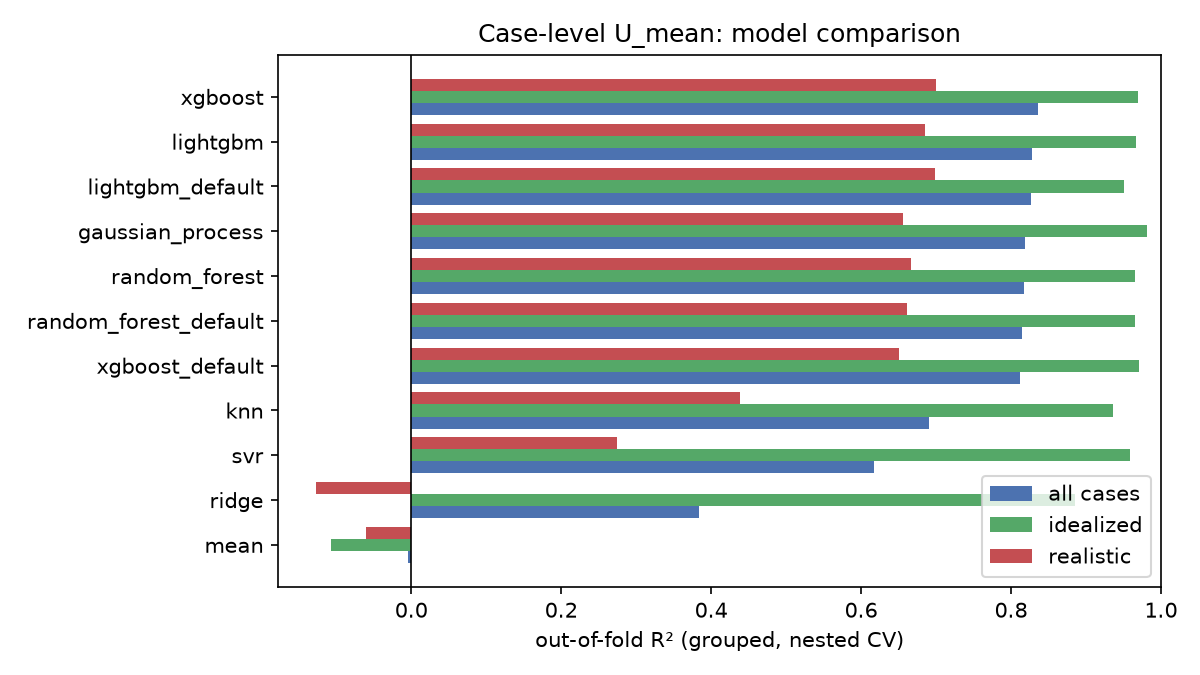

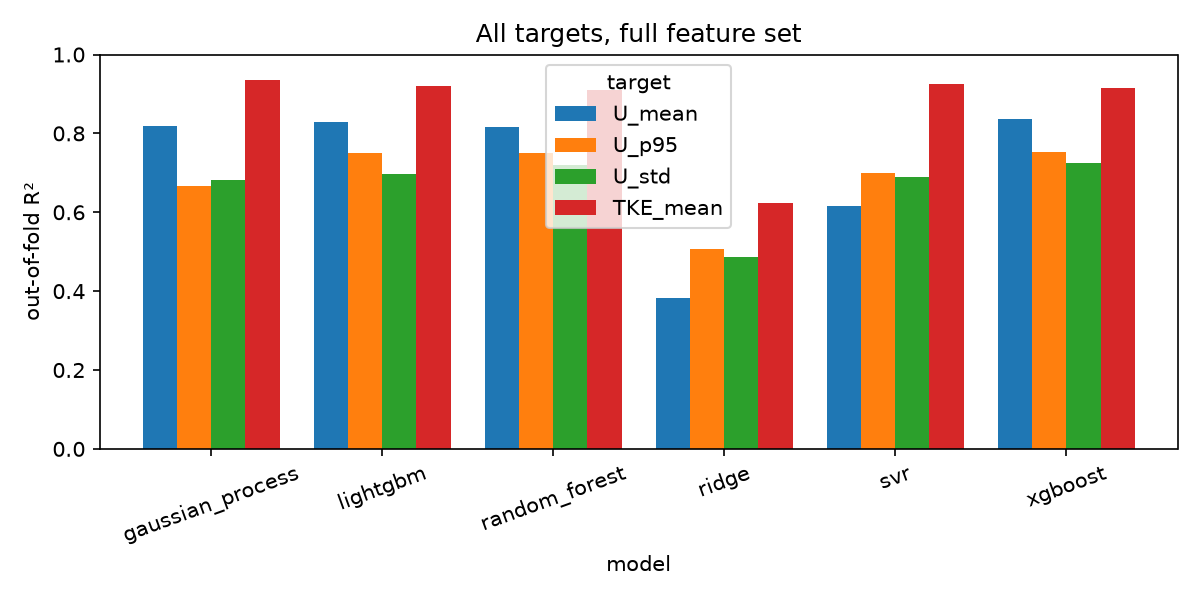

In [3]:
display(Image(FIG / "model_ladder_u_mean.png"))
display(Image(FIG / "model_ladder_all_targets.png"))

### Tuned against default settings

The three tree ensembles are also scored with fixed default settings (500 to 600 trees, library defaults otherwise). Nested tuning adds little except for XGBoost. XGBoost and LightGBM are tuned over the same search space, including a minimum leaf size from 1 to 40 cases. An earlier run gave LightGBM a narrower leaf-size range and made it look 0.06 worse, so how a model is tuned matters as much as which model it is.

In [4]:
tree = table[table["model"].str.replace("_default", "").isin(["random_forest", "xgboost", "lightgbm"]) & (table["features"] == "full")]
display(tree.pivot(index="model", columns="target", values="r2")[["U_mean", "U_p95", "U_std", "TKE_mean"]])

target,U_mean,U_p95,U_std,TKE_mean
model,,,,
lightgbm,0.828,0.751,0.696,0.921
lightgbm_default,0.827,0.731,0.693,0.922
random_forest,0.817,0.749,0.721,0.911
random_forest_default,0.815,0.744,0.710,0.909
xgboost,0.836,0.754,0.724,0.916
xgboost_default,0.811,0.722,0.699,0.895


## 2. Is the difference real? Group bootstrap

The five fold scores are too few for a reliable test, and cases from one city are correlated, so a case-level test would overstate significance. Instead:
- whole split groups (cities and layout families) are resampled 2,000 times with replacement;
- the R² difference between two models is recomputed on each resample.

An interval that excludes 0 means the difference survives this resampling. B1 is the literature-style baseline: an untuned random forest on the nine basic features.

In [5]:
boot = pd.read_csv(OUT / "bootstrap_r2_differences.csv")
display(boot)
display(table[table["model"] == "B1_rf_basic_untuned"][["target", "r2", "r2_idealized", "r2_realistic"]])

,target,model_a,model_b,delta_r2,ci_low,ci_high,p_le_0
0,U_mean,xgboost,B1,0.102,0.052,0.157,0.000
1,U_mean,lightgbm,B1,0.093,0.045,0.151,0.000
2,U_mean,random_forest,B1,0.083,0.033,0.146,0.000
3,U_mean,gaussian_process,B1,0.084,-0.037,0.185,0.069
4,U_mean,xgboost,lightgbm,0.008,-0.019,0.032,0.279
5,U_mean,xgboost,random_forest,0.019,-0.019,0.057,0.172
6,U_mean,lightgbm,random_forest,0.010,-0.035,0.047,0.304
7,U_mean,xgboost,gaussian_process,0.017,-0.056,0.118,0.381
8,U_mean,xgboost_default,lightgbm_default,-0.016,-0.061,0.023,0.747
9,U_p95,xgboost,B1,0.084,0.012,0.160,0.006


,target,r2,r2_idealized,r2_realistic
50,U_mean,0.735,0.890,0.565
51,U_p95,0.670,0.856,0.403
52,U_std,0.595,0.630,0.324
53,TKE_mean,0.865,0.896,0.821


## 3. Which features matter? Ablation and SHAP

The ablation runs the three tree ensembles on three feature sets, each tuned in the same nested loop:
- **basic:** 9 features (λp, height statistics, frontal area, wind direction, subset flag);
- **morphology:** 17 features (plus wall area, height skew and spread, footprint statistics);
- **full:** 34 features (plus displacement height and roughness length from Macdonald and Kanda, fetch, distance to walls, facet orientation).

model,lightgbm,random_forest,xgboost
features,,,
basic,0.599,0.613,0.516
morphology,0.592,0.593,0.587
full,0.686,0.666,0.700


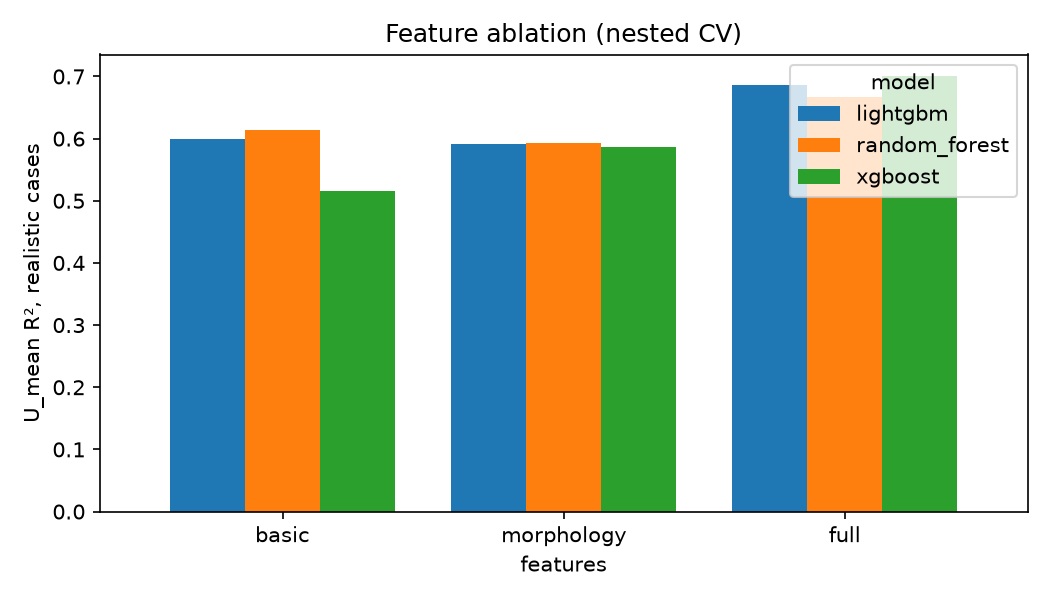

In [6]:
abl = table[table["model"].isin(["random_forest", "xgboost", "lightgbm"]) & (table["target"] == "U_mean")]
display(abl.pivot(index="features", columns="model", values="r2_realistic").loc[["basic", "morphology", "full"]])
display(Image(FIG / "feature_ablation.png"))

TreeSHAP splits each prediction into additive contributions, one per feature. Each outer-fold model explains only its own held-out cases, so the attributions describe generalisation to unseen cities, not memorised training cases.

,model,feature,mean_abs_shap
0,xgboost,lambda_f_dir,0.128
1,xgboost,dist_mean_m,0.128
2,xgboost,upwind_fetch_mean_m,0.080
3,xgboost,dist_p90_m,0.079
4,xgboost,volume_per_area_m,0.076
5,xgboost,lateral_fetch_mean_m,0.057
6,xgboost,z0_over_h_kanda,0.041
7,xgboost,z0_over_h_macdonald,0.028
8,xgboost,max_h,0.026
9,xgboost,components_per_hectare,0.025


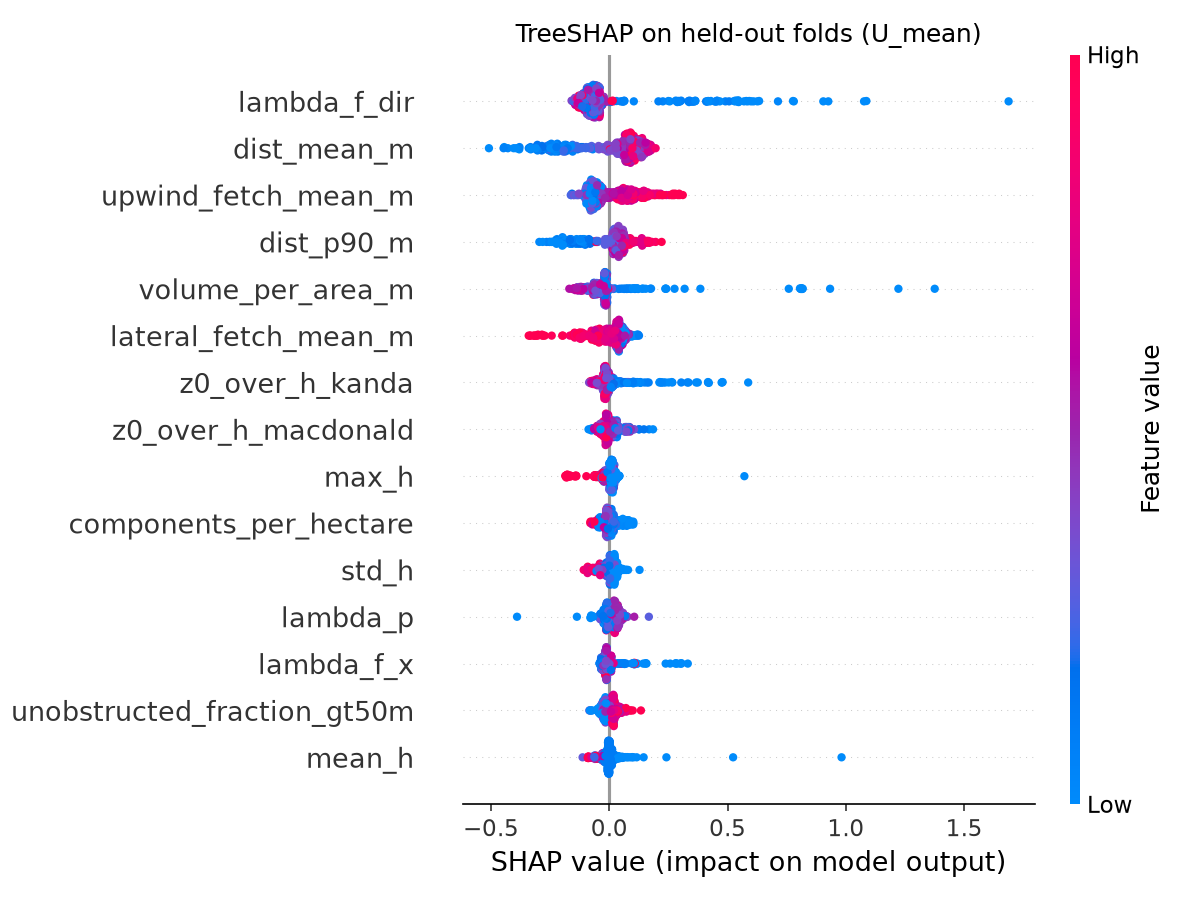

In [7]:
display(pd.read_csv(OUT / "shap_importance_u_mean.csv").head(15))
display(Image(FIG / "shap_u_mean.png"))

## 4. How optimistic are random splits?

The same untuned models are scored with random 5-fold CV (averaged over five shuffles) and with the grouped folds. The gap is evaluated on realistic cases, because there neighbouring cases share a city. It measures how much a random split flatters a model on cities it has already seen.

,model,r2_random_kfold,r2_grouped
0,ridge,0.382,-0.071
1,knn,0.339,0.326
2,random_forest,0.688,0.661
3,lightgbm,0.736,0.698


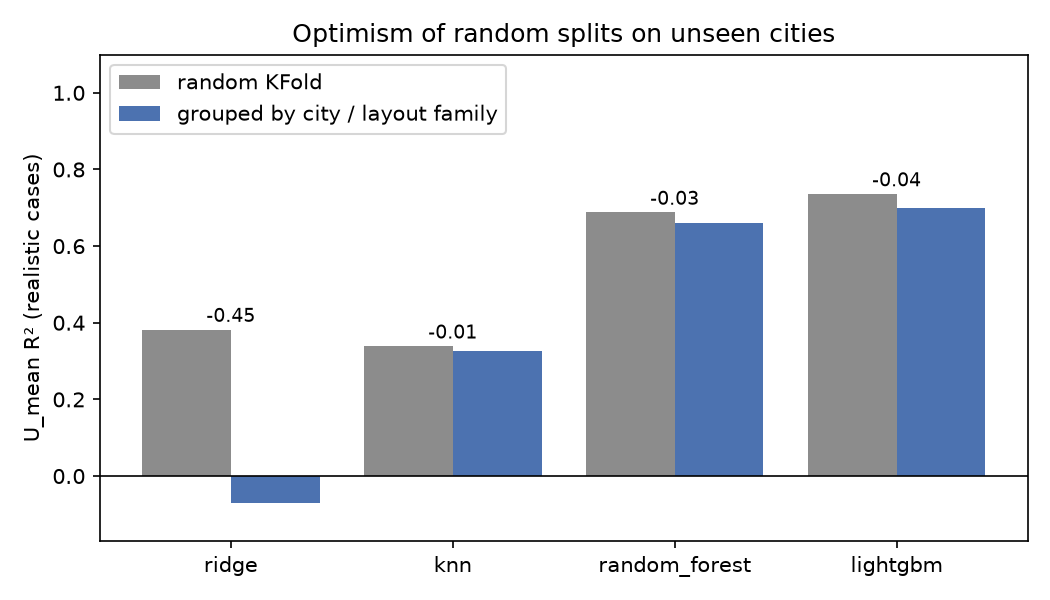

In [8]:
display(pd.read_csv(OUT / "leakage_random_vs_grouped.csv"))
display(Image(FIG / "leakage_random_vs_grouped.png"))

## 5. Transfer between subsets

An untuned LightGBM is trained on one subset only and tested on the other, then compared with grouped CV inside the test subset.

In [9]:
display(pd.read_csv(OUT / "transfer.csv"))

,train,test,r2_transfer,r2_within_subset_cv
0,idealized,realistic,0.092,0.686
1,realistic,idealized,-0.467,0.967


## 6. Predictions against the simulations

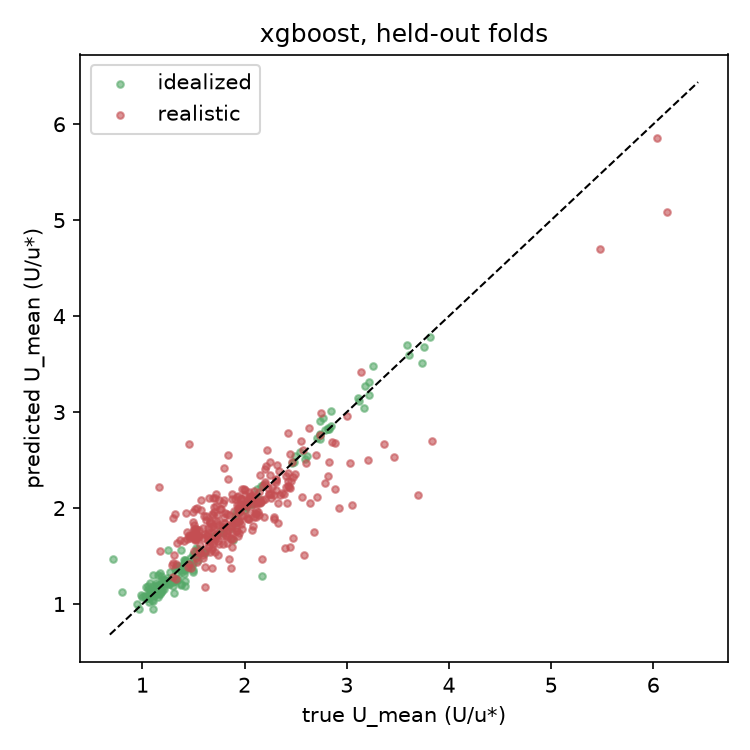

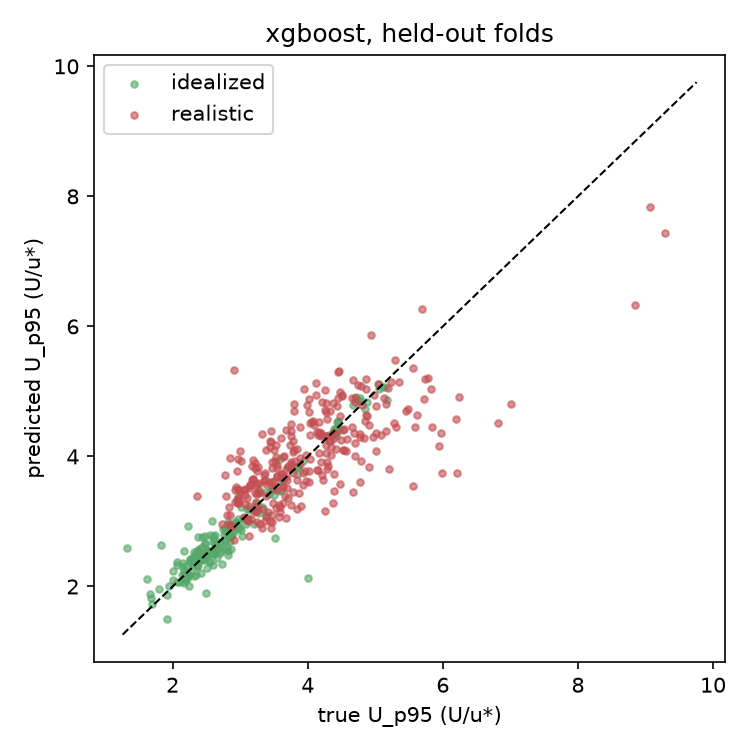

In [10]:
display(Image(FIG / "parity_U_mean.png"))
display(Image(FIG / "parity_U_p95.png"))

## 7. Scoring through the shared evaluator

Each model's out-of-fold predictions are written to `results/preds/s06c_<model>/case_preds.csv` and scored by `python -m urbanwind.evaluate`, which appends a row to `results/runs.csv`.